In [1]:
import cv2 
import numpy as np 
import  matplotlib.pyplot  as  plt 

In [15]:
cap =cv2.VideoCapture(r'Data\vtest.avi')

In [3]:
cap

< cv2.VideoCapture 000001E5D6FB8330>

In [4]:
cap.get(cv2.CAP_PROP_FRAME_COUNT)

795.0

In [5]:
cap.get(cv2.CAP_PROP_FPS)

10.0

In [16]:
# speed  
original_FPS  =  cap.get(cv2.CAP_PROP_FPS) 
speed_factor = 3.0

In [17]:
delay  =  int((1000 / original_FPS) / speed_factor)

In [18]:

while cap.isOpened() : 
    flag  , frame  = cap.read()

    if not flag :
        break

    cv2.imshow('video' , frame)  

    if  cv2.waitKey(delay)  &  0xFF ==ord('d') :
        break 

    if  cv2.getWindowProperty('video' ,cv2.WND_PROP_VISIBLE)  < 1 : 
        break



cap.release()
cv2.destroyAllWindows()    

In [19]:
#  object  tracking  

In [20]:
cap =cv2.VideoCapture(r'Data\vtest.avi')

In [21]:
#  smaple  frames  
sample_frames  =  cap.get(cv2.CAP_PROP_FRAME_COUNT) * np.random.uniform(size=  30)

In [22]:
sample_frames

array([122.83856674, 228.04238939, 320.31489977, 301.03952025,
       176.39257529,  36.10636432, 568.56576586, 462.64782902,
       770.64485417, 237.30065273, 327.39282523, 708.56740101,
        45.07914998, 443.74818737,  83.23944965, 108.01644981,
       351.67421439, 708.96034782, 299.66246355, 307.71932957,
       110.22658545, 467.46928105, 112.89061551,  39.36040047,
       606.61272343, 630.47445103, 508.97657655,  81.12936455,
       743.94351921, 421.34242134])

In [23]:
frames = [] 
for id_frame  in  sample_frames :  
    cap.set(cv2.CAP_PROP_POS_FRAMES, id_frame )
    flage ,  frame  =  cap.read()
    frames.append(frame)

cap.release()    

In [24]:
len(frames)

30

In [26]:
# frames

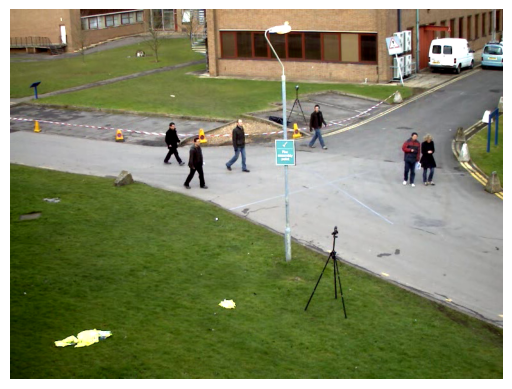

In [28]:
frame_rgb = cv2.cvtColor(frames[10] , cv2.COLOR_BGR2RGB)
plt.imshow(frame_rgb)
plt.axis('off')
plt.show()

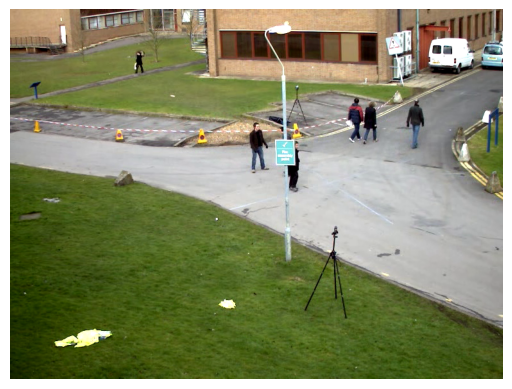

In [29]:
frame_rgb = cv2.cvtColor(frames[20] , cv2.COLOR_BGR2RGB)
plt.imshow(frame_rgb)
plt.axis('off')
plt.show()

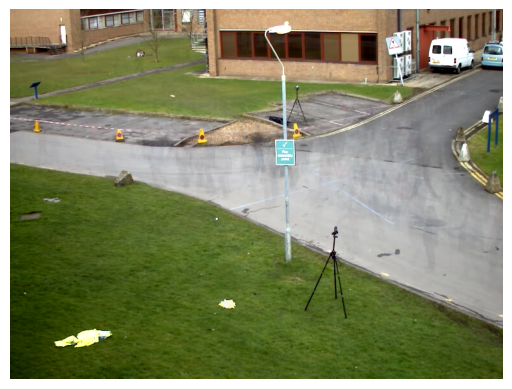

In [30]:
#  get  background  

avg_bg  =  np.average(frames , axis=0).astype('uint8')
frame_rgb = cv2.cvtColor(avg_bg , cv2.COLOR_BGR2RGB)
plt.imshow(frame_rgb)
plt.axis('off')
plt.show()

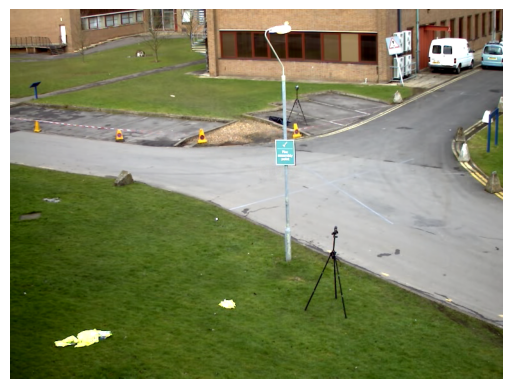

In [31]:

avg_bg  =  np.median(frames , axis=0).astype('uint8')
frame_rgb = cv2.cvtColor(avg_bg , cv2.COLOR_BGR2RGB)
plt.imshow(frame_rgb)
plt.axis('off')
plt.show()

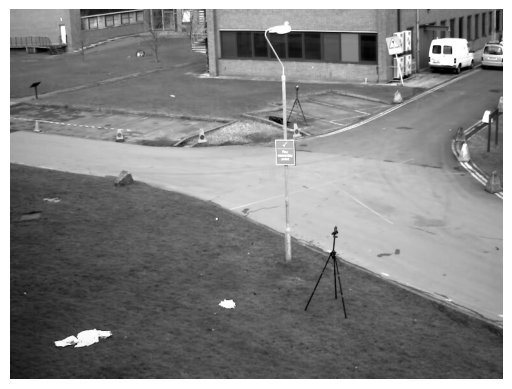

In [37]:
# gray 
median_bg  =  np.median(frames , axis=0).astype('uint8')
bg_gray = cv2.cvtColor(median_bg , cv2.COLOR_BGR2GRAY)
plt.imshow(bg_gray,  cmap='gray')
plt.axis('off')
plt.show()

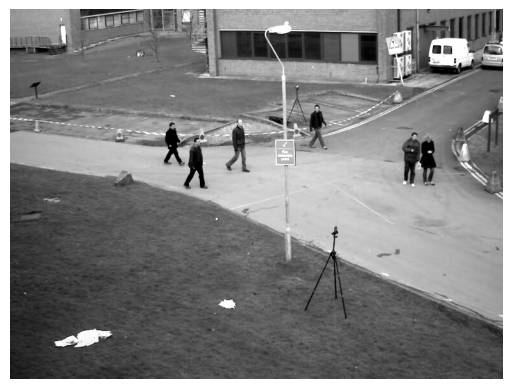

In [38]:
frame_gray = cv2.cvtColor(frames[10] , cv2.COLOR_BGR2GRAY)
plt.imshow(frame_gray , cmap= 'gray')
plt.axis('off')
plt.show()

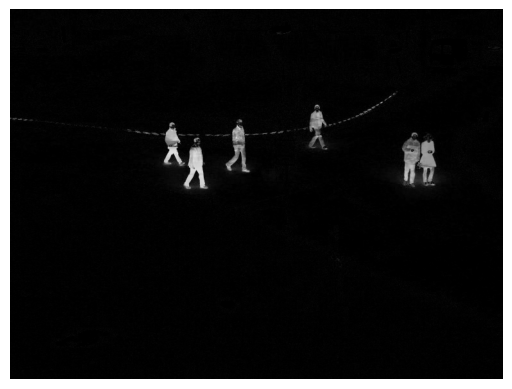

In [39]:
remove_bg =  cv2.absdiff(frame_gray , bg_gray)
plt.imshow(remove_bg , cmap= 'gray')
plt.axis('off')
plt.show()

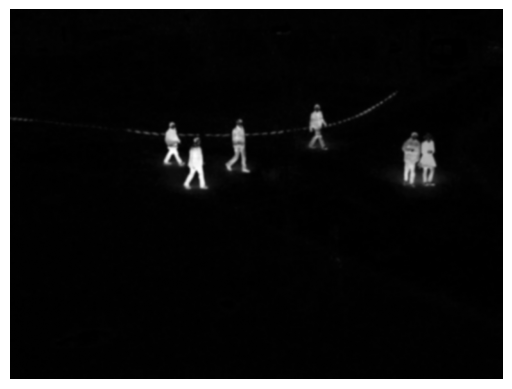

In [54]:
# blur  
blur_remove_bg =  cv2.GaussianBlur(remove_bg , (7,7) , 0)
plt.imshow(blur_remove_bg , cmap= 'gray')
plt.axis('off')
plt.show()

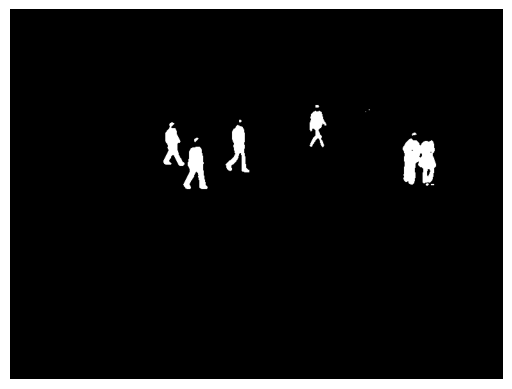

In [55]:
# treeshold   convert  image  to binary image  
_ ,   binary_image  = cv2.threshold(blur_remove_bg , 0 , 255 , cv2.THRESH_BINARY + cv2.THRESH_OTSU  )
plt.imshow(binary_image , cmap= 'gray')
plt.axis('off')
plt.show()

In [56]:
#  contours 
(contours  , _) =   cv2.findContours(binary_image , cv2.RETR_EXTERNAL , cv2.CHAIN_APPROX_SIMPLE )

In [50]:
# contours

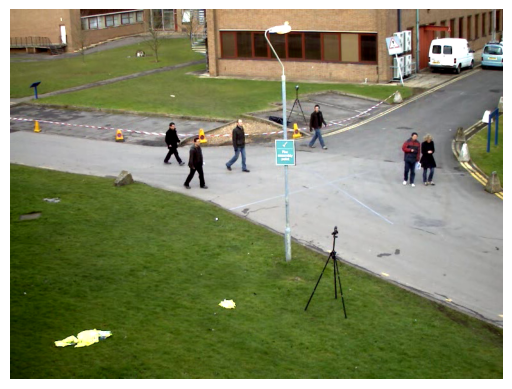

In [51]:
frame_rgb = cv2.cvtColor(frames[10] , cv2.COLOR_BGR2RGB)
plt.imshow(frame_rgb)
plt.axis('off')
plt.show()

In [57]:
for  c  in contours :  
    x, y  , w , h   =  cv2.boundingRect(c)
    cv2.rectangle(frame_rgb , (x,y) ,(x+w , y+h), (0,255,0) ,  2)

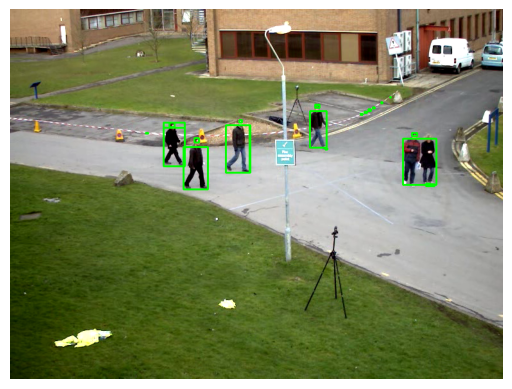

In [58]:
plt.imshow(frame_rgb)
plt.axis('off')
plt.show()

In [3]:
background_remover  = cv2.createBackgroundSubtractorMOG2()
cap =cv2.VideoCapture(r'Data\vtest.avi')
while cap.isOpened() : 
    flag ,  frame  =  cap.read()
    if  not  flag : 
        break 

    masked_fr =  background_remover.apply(frame)
    #  contours 
    (contours  , _) =   cv2.findContours(masked_fr , cv2.RETR_EXTERNAL , cv2.CHAIN_APPROX_SIMPLE )
    for  c  in contours : 
        if cv2.contourArea(c) > 500:   
            x, y  , w , h   =  cv2.boundingRect(c)
            cv2.rectangle(frame , (x,y) ,(x+w , y+h), (0,255,0) ,  2)

    cv2.imshow('object tracking' ,frame )  

    if  cv2.waitKey(30)  &  0xFF ==ord('d') :
            break 
    
    # if  cv2.getWindowProperty('video' ,cv2.WND_PROP_VISIBLE)  < 1 : 
    #     break  

cap.release()
cv2.destroyAllWindows()    